# §5.3 — Identificação do padrão de escoamento (Figuras 22–23, Tabelas 13–14)

Mapas ar–água de 2,5 cm, horizontal e vertical, classificados ponto a ponto nas mesmas
velocidades superficiais que a dissertação (os marcadores digitalizados das Figuras 22–23),
com as curvas de transição tracejadas sobrepostas. Acerto por classe e efeito das opções
decididas na issue 003.

== Figura 22 (horizontal): acerto global 91.4%
| padrão (dissertação) | pontos | acerto cmfsim |
|---|---|---|
| bubble | 162 | 100% |
| intermittent | 66 | 73% |
| annular | 107 | 93% |
| stratified | 60 | 85% |


figura: notebooks/figs/nb_5_3_fig22_map.png


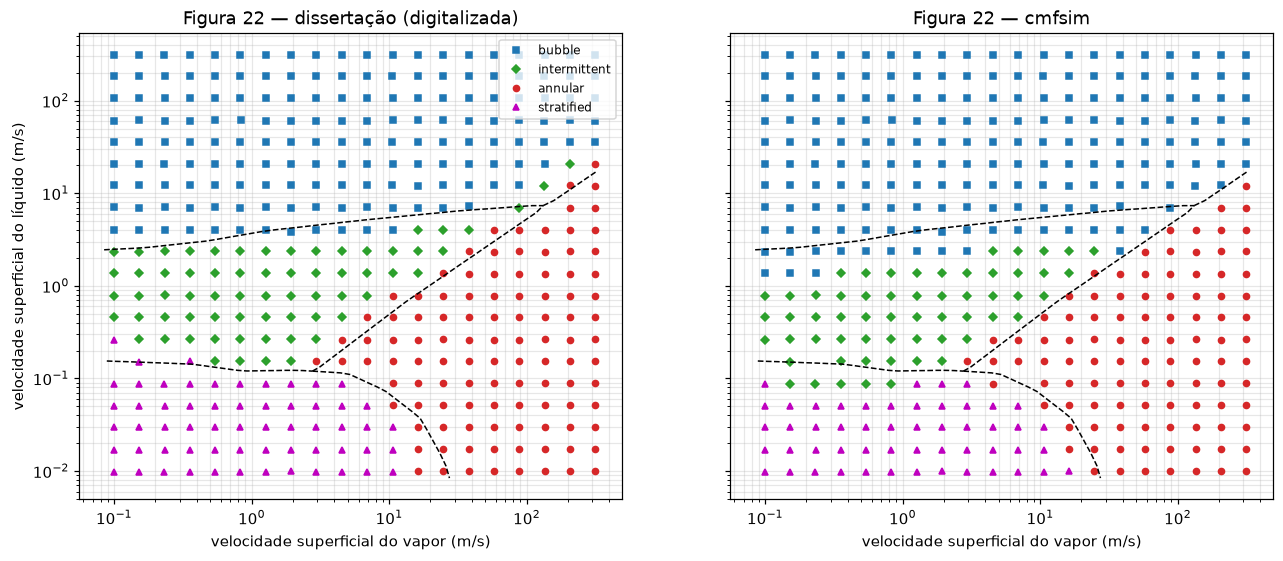

== Figura 23 (vertical): acerto global 95.5%
| padrão (dissertação) | pontos | acerto cmfsim |
|---|---|---|
| bubble | 104 | 100% |
| intermittent | 134 | 87% |
| annular | 160 | 100% |
figura: notebooks/figs/nb_5_3_fig23_map.png


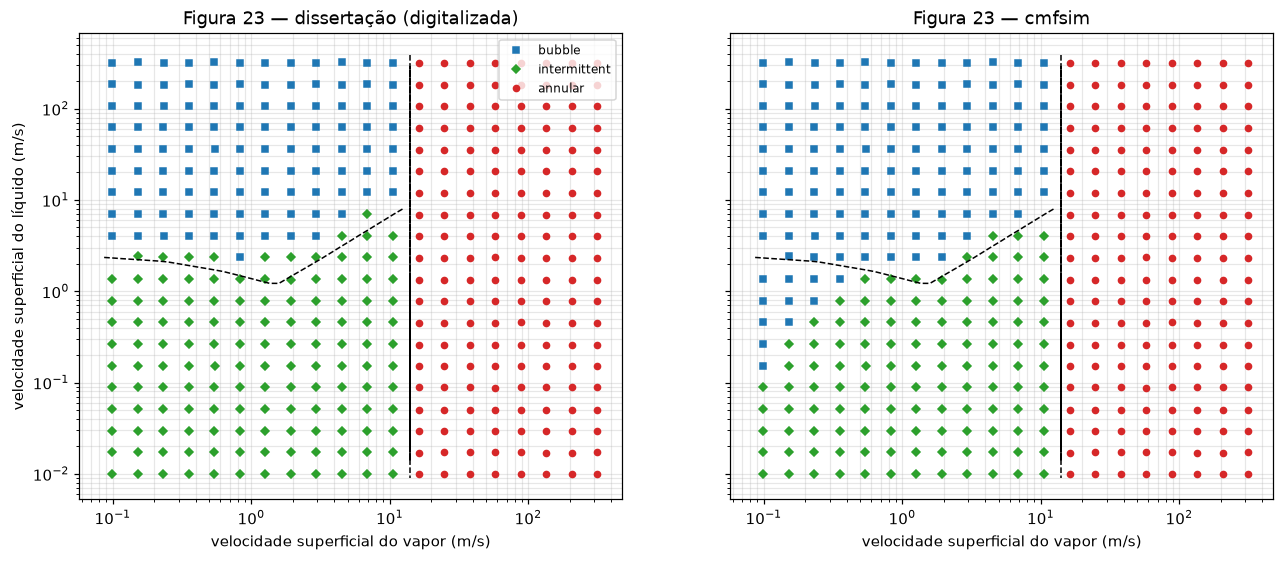

In [1]:
import numpy as np

import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(ROOT))

from dissertation.notebook_utils import figure, plt, save, table, tables

from cmfsim.backend import NUMPY
from cmfsim.closures import PATTERNS, ClosureOptions, FlowInputs, flow_closure

t13 = tables()["table13_air_water"]
t14 = tables()["table14_pattern_pipes"]
LABEL = {"bolhas": "bubble", "intermitente": "intermittent", "anular": "annular", "estratificado": "stratified"}
MARK = {"bubble": ("s", "C0"), "intermittent": ("D", "C2"), "annular": ("o", "C3"), "stratified": ("^", "m")}


def classes(fig):
    out = {}
    for nm, (x, y) in fig["series"].items():
        low = nm.lower()
        if "cadeia" in low:
            continue
        for key, lab in LABEL.items():
            if key in low:
                out[lab] = (x, y)
    return out


def classify(theta, xs, ys, opts, sigma=0.072):
    inp = FlowInputs.build(
        bk=NUMPY,
        D=t14["D"],
        eps=t14["roughness"],
        theta=theta,
        rho_L=t13["rho_water"],
        rho_G=t13["rho_air"],
        mu_L=t13["mu_water"],
        mu_G=t13["mu_air"],
        sigma=sigma,
        v_SL=ys,
        v_SG=xs,
    )
    _, w = flow_closure(inp, opts)
    return np.array([PATTERNS[i] for i in np.argmax(w, axis=1)])


for n, theta, title in ((22, 0.0, "horizontal"), (23, np.pi / 2, "vertical")):
    fig_d = figure(n)
    cl = classes(fig_d)
    xs = np.concatenate([v[0] for v in cl.values()])
    ys = np.concatenate([v[1] for v in cl.values()])
    labels = np.concatenate([[k] * len(v[0]) for k, v in cl.items()])
    opts = ClosureOptions(k_switch=None)
    mine = classify(theta, xs, ys, opts)
    acc = np.mean(mine == labels)
    rows = [(k, int((labels == k).sum()), f"{np.mean(mine[labels == k] == k):.0%}") for k in cl]
    print(f"== Figura {n} ({title}): acerto global {acc:.1%}")
    table(rows, ["padrão (dissertação)", "pontos", "acerto cmfsim"])
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
    for ax, lab_set, ttl in ((axes[0], labels, "dissertação (digitalizada)"), (axes[1], mine, "cmfsim")):
        for k, (mk, c) in MARK.items():
            m = lab_set == k
            if m.any():
                ax.loglog(xs[m], ys[m], mk, color=c, ms=4, label=k)
        for nm, (x, y) in fig_d["series"].items():
            if "cadeia" in nm.lower():
                ax.loglog(x, y, "k--", lw=1)
        ax.set_title(f"Figura {n} — {ttl}")
        ax.set_xlabel("velocidade superficial do vapor (m/s)")
        ax.grid(alpha=0.3, which="both")
    axes[0].set_ylabel("velocidade superficial do líquido (m/s)")
    axes[0].legend(fontsize=8)
    save(fig, f"nb_5_3_fig{n}_map")

## Sensibilidade às leituras do texto (issue 003)

In [2]:
f23 = figure(23)
cl = classes(f23)
xs = np.concatenate([v[0] for v in cl.values()])
ys = np.concatenate([v[1] for v in cl.values()])
labels = np.concatenate([[k] * len(v[0]) for k, v in cl.items()])
rows = []
for name, kw, sigma in (
    ("default (limite de vazio 0,52; σ 0,072)", {}, 0.072),
    ("sem limite de vazio (como impresso)", {"dispersed_max_void": None}, 0.072),
    ("bolhas só em tubos largos (Taitel, ≥ 4,36)", {"bubble_existence": "taitel"}, 0.072),
    ("σ = 0,0072 N/m (Tabela 13 como impressa)", {}, 0.0072),
):
    mine = classify(np.pi / 2, xs, ys, ClosureOptions(k_switch=None, **kw), sigma)
    rows.append((name, f"{np.mean(mine == labels):.1%}"))
table(rows, ["variante (vertical, Figura 23)", "acerto"])

| variante (vertical, Figura 23) | acerto |
|---|---|
| default (limite de vazio 0,52; σ 0,072) | 95.5% |
| sem limite de vazio (como impresso) | 83.2% |
| bolhas só em tubos largos (Taitel, ≥ 4,36) | 98.7% |
| σ = 0,0072 N/m (Tabela 13 como impressa) | 93.0% |
